# Learning rate: is it too large?
Decision 16. At lr 1e-5 (run1_5ep) the validation minimum was 3.418 at step 2,500 while train kept dropping. Is the learning rate too large?

- run2: lr 1e-4, 3 epochs (4,053 steps).
- run3: lr 3e-6, 5 epochs (6,755 steps), when it finishes.
- Selection metric as in decision 15: `nll_ejemplo` on the FULL session `valid`. "The same" means within ~0.01-0.02 of 3.418 (decision 14).

_My prediction (written in DECISIONS.md, decision 16, before seeing any result):_ the learning rate is too large. Train drops a lot and validation barely moves, so the model goes straight into memorizing train before finding what generalizes. A lower lr (3e-6) should give a validation minimum clearly below 3.418.

In [1]:
import json, math
import mlx.core as mx
from mlx_lm import load

MODELO = "mlx-community/Qwen2.5-0.5B-Instruct-4bit"
EJEMPLOS_TRAIN = 5404  # session train size; epoch = step * 4 / 5404

In [2]:
# Copied as is from Perplexity.ipynb
def nll_ejemplo(model, tokenizer, messages):
    full = tokenizer.apply_chat_template(messages)
    base_prompt = tokenizer.apply_chat_template(
        messages[:-1], add_generation_prompt=True)
    n_tokens = len(full) - len(base_prompt)
    logits = model(mx.array(full)[None])
    logits = logits[0, len(base_prompt)-1:len(full)-1]
    logits = logits.astype(mx.float32)
    logprobs = logits - mx.logsumexp(logits, axis=-1, keepdims=True)
    nll = 0
    for i in range(n_tokens):
        nll -= logprobs[i, full[len(base_prompt) + i]].item()
    mx.clear_cache()
    return (nll, n_tokens)

def medir(model, tokenizer, ruta):
    with open(ruta, "r") as f:
        ejemplos = [json.loads(line) for line in f if line.strip()]
    return [nll_ejemplo(model, tokenizer, e["messages"]) for e in ejemplos]

In [3]:
def resumen(resultados):
    nll = sum(r[0] for r in resultados)
    n = sum(r[1] for r in resultados)
    return nll / n

def curva(adaptador, ruta_valid, pasos):
    """Loss of every checkpoint in pasos, loading each one's weights over the same model."""
    model, tokenizer = load(MODELO, adapter_path=adaptador)
    perdidas = {}
    for paso in pasos:
        model.load_weights(f"{adaptador}/{paso:07d}_adapters.safetensors", strict=False)
        perdidas[paso] = resumen(medir(model, tokenizer, ruta_valid))
        print(f"step {paso:>4}: loss {perdidas[paso]:.3f}")
    return perdidas

In [4]:
import random

def muestra_train(ruta, n, semilla=0):
    """Same number of train examples as valid, chosen at random, written to a temp file so curva() can read it."""
    with open(ruta) as f:
        lineas = [l for l in f if l.strip()]
    elegidas = random.Random(semilla).sample(lineas, n)
    salida = ruta.replace("train.jsonl", "train_sample.jsonl")
    with open(salida, "w") as f:
        f.writelines(elegidas)
    return salida

TRAIN_SESSION = muestra_train("../data/dataset/session/train.jsonl", 1012)  # same sample as Checkpoints.ipynb (seed 0)

## lr 1e-5 (run1_5ep, from Checkpoints.ipynb)

In [5]:
with open("results/checkpoints_lr1e-5.json") as f:
    lr1e5 = json.load(f)
valid_1e5 = {int(k): v for k, v in lr1e5["valid_run1"].items()}
train_1e5 = {int(k): v for k, v in lr1e5["train_run1"].items()}
valid_bm_1e5 = {int(k): v for k, v in lr1e5["valid_by_message"].items()}  # available, not plotted
print("best at 1e-5:", lr1e5["best_run1"])

best at 1e-5: {'step': 2500, 'valid_loss': 3.418}


## Helpers: measure and plot one run
Each run section below calls these, so no cell has to be edited between runs.

In [6]:
import matplotlib.pyplot as plt

VALID_SESSION = "../data/dataset/session/valid.jsonl"

def medir_run(adaptador, run, lr, pasos):
    """Measures valid and the train sample on every checkpoint, saves results/checkpoints_lr{lr}.json and returns the dict."""
    print(f"{run} (lr {lr}): validation")
    valid = curva(adaptador, VALID_SESSION, pasos)
    print(f"{run} (lr {lr}): train sample")
    train = curva(adaptador, TRAIN_SESSION, pasos)
    mejor = min(valid, key=valid.get)
    resultados = {
        "source": "experiments/LearningRate.ipynb",
        "model": MODELO,
        "learning_rate": float(lr),
        f"valid_{run}": valid,
        f"train_{run}": train,
        f"best_{run}": {"step": mejor, "valid_loss": valid[mejor]},
    }
    salida = f"results/checkpoints_lr{lr}.json"
    with open(salida, "w") as f:
        json.dump(resultados, f, indent=2)
    print("saved", salida)
    return resultados

def epocas(curva_):
    return [p * 4 / EJEMPLOS_TRAIN for p in curva_]

def graficar_run(resultados, run):
    """Left: validation vs epoch against lr 1e-5. Right: train vs validation for this run."""
    lr = f"{resultados['learning_rate']:.0e}".replace("e-0", "e-")  # 0.0001 -> "1e-4"
    valid = {int(k): v for k, v in resultados[f"valid_{run}"].items()}
    train = {int(k): v for k, v in resultados[f"train_{run}"].items()}
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
    ejes[0].plot(epocas(valid_1e5), list(valid_1e5.values()), marker="o", label="lr 1e-5 (run1_5ep)")
    ejes[0].plot(epocas(valid), list(valid.values()), marker="o", label=f"lr {lr} ({run})")
    ejes[0].axhline(3.418, color="gray", linestyle="--", linewidth=1, label="best at 1e-5 (3.418)")
    ejes[0].set_title("validation"); ejes[0].set_xlabel("epoch"); ejes[0].set_ylabel("loss (nll_ejemplo)"); ejes[0].legend()

    ejes[1].plot(epocas(train), list(train.values()), marker="o", label="train (sample)")
    ejes[1].plot(epocas(valid), list(valid.values()), marker="o", label="validation")
    ejes[1].set_title(f"lr {lr} ({run})"); ejes[1].set_xlabel("epoch"); ejes[1].legend()
    plt.show()

## Run 2: lr 1e-4
4,053 steps (~3 epochs), checkpoints every 100; measured every 200 up to 3,000.

In [7]:
run2 = medir_run("../adapters/run2_lr1e-4", "run2", "1e-4", list(range(200, 3001, 200)))
print("best:", run2["best_run2"])

run2 (lr 1e-4): validation


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  200: loss 3.952
step  400: loss 3.807
step  600: loss 3.737
step  800: loss 3.682
step 1000: loss 3.617
step 1200: loss 3.586
step 1400: loss 3.629
step 1600: loss 3.715
step 1800: loss 3.690
step 2000: loss 3.637
step 2200: loss 3.674
step 2400: loss 3.648
step 2600: loss 3.618
step 2800: loss 3.940
step 3000: loss 3.821
run2 (lr 1e-4): train sample


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  200: loss 3.740
step  400: loss 3.536
step  600: loss 3.365
step  800: loss 3.218
step 1000: loss 3.115
step 1200: loss 3.017
step 1400: loss 2.852
step 1600: loss 2.828
step 1800: loss 2.744
step 2000: loss 2.710
step 2200: loss 2.630
step 2400: loss 2.541
step 2600: loss 2.478
step 2800: loss 2.306
step 3000: loss 2.253
saved results/checkpoints_lr1e-4.json
best: {'step': 1200, 'valid_loss': 3.586341163598265}


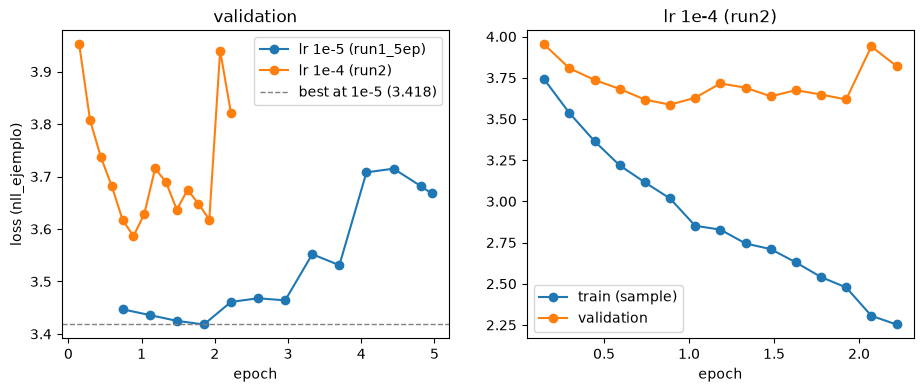

In [8]:
graficar_run(run2, "run2")

## Run 3: lr 3e-6
6,755 steps (5 epochs); measured every 500 plus 6,700. Run this section once training has finished: it only needs the setup cells at the top, not run 2's cells.

In [9]:
run3 = medir_run("../adapters/run3_lr3e-6", "run3", "3e-6", list(range(500, 6501, 500)) + [6700])
print("best:", run3["best_run3"])

run3 (lr 3e-6): validation


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: loss 3.575
step 1000: loss 3.520
step 1500: loss 3.492
step 2000: loss 3.473
step 2500: loss 3.456
step 3000: loss 3.447
step 3500: loss 3.443
step 4000: loss 3.435
step 4500: loss 3.448
step 5000: loss 3.433
step 5500: loss 3.442
step 6000: loss 3.452
step 6500: loss 3.445
step 6700: loss 3.435
run3 (lr 3e-6): train sample


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

step  500: loss 3.494
step 1000: loss 3.399
step 1500: loss 3.341
step 2000: loss 3.292
step 2500: loss 3.241
step 3000: loss 3.202
step 3500: loss 3.167
step 4000: loss 3.130
step 4500: loss 3.107
step 5000: loss 3.056
step 5500: loss 3.022
step 6000: loss 2.990
step 6500: loss 2.958
step 6700: loss 2.950
saved results/checkpoints_lr3e-6.json
best: {'step': 5000, 'valid_loss': 3.4329303807286458}


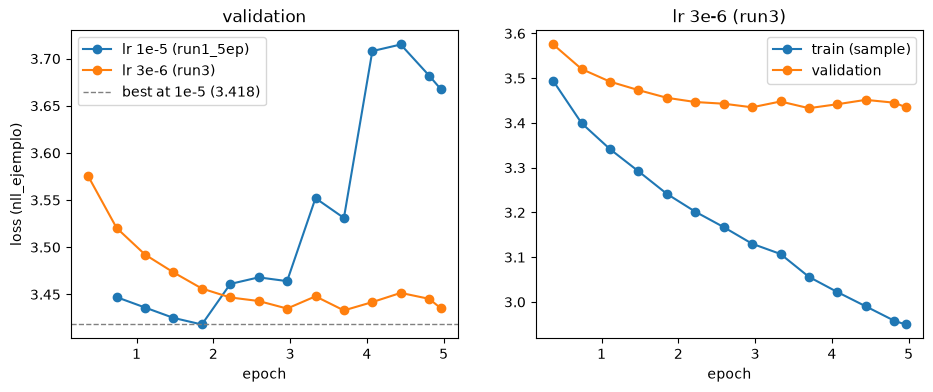

In [12]:
graficar_run(run3, "run3")

## All learning rates together
Loads every saved `results/checkpoints_lr*.json` and overlays the validation curves. Needs only the setup and helper cells above, not the run sections.

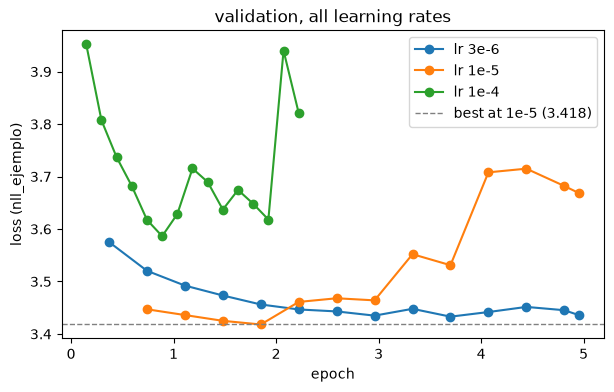

    lr best step  epoch valid nll
  3e-6      5000   3.70     3.433
  1e-5      2500   1.85     3.418
  1e-4      1200   0.89     3.586


In [13]:
import glob

def curva_valid(datos):
    """Session-split validation curve: the valid_runN key (not valid_by_message)."""
    claves = [k for k in datos if k.startswith("valid_") and k != "valid_by_message"]
    if not claves:
        return None
    return {int(p): v for p, v in datos[claves[0]].items()}

curvas = {}
for ruta in glob.glob("results/checkpoints_lr*.json"):
    lr = ruta.split("checkpoints_lr")[-1].removesuffix(".json")  # "1e-5"
    with open(ruta) as f:
        c = curva_valid(json.load(f))
    if c:
        curvas[lr] = dict(sorted(c.items()))

fig, eje = plt.subplots(figsize=(7, 4))
for lr in sorted(curvas, key=float):
    c = curvas[lr]
    eje.plot(epocas(c), list(c.values()), marker="o", label=f"lr {lr}")
eje.axhline(3.418, color="gray", linestyle="--", linewidth=1, label="best at 1e-5 (3.418)")
eje.set_title("validation, all learning rates"); eje.set_xlabel("epoch"); eje.set_ylabel("loss (nll_ejemplo)"); eje.legend()
plt.show()

print(f"{'lr':>6} {'best step':>9} {'epoch':>6} {'valid nll':>9}")
for lr in sorted(curvas, key=float):
    c = curvas[lr]
    paso = min(c, key=c.get)
    print(f"{lr:>6} {paso:>9} {paso * 4 / EJEMPLOS_TRAIN:>6.2f} {c[paso]:>9.3f}")

### Conclusion

| lr | best step | epochs | valid nll |
|---|---|---|---|
| 3e-6 | 5000 | 3.70 | 3.433 |
| 1e-5 | 2500 | 1.85 | 3.418 |
| 1e-4 | 1200 | 0.89 | 3.586 |

With the smallest lr training is more stable: validation stays flat between 3.43 and 3.45 from step 3000 on and doesn't go up, and the train/valid gap is much smaller. But it doesn't reach the 1e-5 minimum (3.433 vs 3.418, practically the same: within the ~0.01-0.02 used as "the same" in decision 14). 1e-4 is clearly worse: its minimum is 3.586, under one epoch, and then it overfits.

My prediction was wrong. A lower lr reaches the same minimum, only later (3.433 at step 5000 vs 3.418 at 2500), and a higher lr makes it worse. Below 1e-5 the lr is not the bottleneck; above it, it hurts.

Since 3e-6 barely overfits and still stops at ~3.43, the ceiling doesn't look like an overfitting problem. Shrinking the LoRA (rank, layers) or adding dropout should make training more stable, but probably won't lower the minimum. Next step: more context per example.